# Comparison with IMERG: figures for the article

ERA5, CRCM6-ERA5 and IMERG on the ERA5 grid, 2001–2014 (Sect. 3.1.2). EEcum is the accumulated extreme exceedance
of precipitation associated with ETCs (total − p99 × count, within 1000 km of a cyclone).
- **Main figure:** (a) ERA5 − IMERG and (b) CRCM6-ERA5 − IMERG, with the contours of the EEcum of IMERG and the
  hatching of the non-significant differences (paired t-test, FDR 0.10); (c) |ERA5 − IMERG| − |CRCM6-ERA5 − IMERG|, > 0 where
  CRCM6-ERA5 is closer to IMERG than ERA5.
- **Supplementary figure:** the same two differences and their three terms, as Fig. 3 of the article (biases
  relative to ERA5), with IMERG as the reference.

Plotting functions and layout of `plot_map_ETCs_diff_w_ERA5.ipynb`: its imports and functions cells are run here,
and the panels have the positions, sizes and fonts of `plot_map_four_per_four` (figure of 16 x 16 inches, empty
part cropped when saving). Colour scales and contour steps of the article (35 years) times 14/35.

`MASK_NORTH_OF` (default `None`): latitude north of which the maps are masked, e.g. 60 as in Chen and Di Luca (2025).
Not used for the article, which shows the north of the domain, where IMERG is less reliable, and discusses it.

Inputs: outputs of `POSTPROCESSING/regrid_IMERG_evaluation.ipynb`. Outputs, in `ALL/PLOT/IMERG/`:
`fig_PR_vs_IMERG_2001-2014.png` and `figS_terms_PR_vs_IMERG_2001-2014.png` (with `_north<lat>masked` if masked).
Both notebooks are run by `JOBS/run_IMERG_evaluation.sh`.

In [1]:
import json
import os
import pickle
import numpy as np
import xarray as xr

PLOT_DIR = '/home/vdemeyer/TRACKING/KATJA/PLOT'
BASE = '/home/vdemeyer/projects/rrg-gachon/vdemeyer'
OUT_DIR = f'{BASE}/ALL/PLOT/IMERG'
PERIOD = '2001-2014'
MASK_NORTH_OF = None                    # e.g. 60: mask the maps north of 60N (not used for the article)
TAG = '_noTC'
Q = 0.99
DIMS = ('latitude', 'longitude')
SIGMA = 7                               # smoothing of the contours on the ERA5 grid, as in the article
FIRST, LAST = map(int, PERIOD.split('-'))
SCALE = (LAST - FIRST + 1) / 35         # colour scales of the article (1980-2014) for the years of PERIOD
MASK_TAG = f'_north{MASK_NORTH_OF}masked' if MASK_NORTH_OF is not None else ''
os.makedirs(OUT_DIR, exist_ok=True)

# Plotting functions of plot_map_ETCs_diff_w_ERA5.ipynb: its imports cell and its functions cell, run as they are,
# without the first line of the latter (a mask computed from the data of that notebook, not used by the functions)
with open(f'{PLOT_DIR}/plot_map_ETCs_diff_w_ERA5.ipynb') as f:
    _code = [''.join(c['source']) for c in json.load(f)['cells'] if c['cell_type'] == 'code']
assert _code[3].startswith('mask = data[')
exec(_code[0])
exec(_code[3].split('\n', 1)[1])
plt.rcParams['figure.dpi'] = 50         # display in the notebook only; the files are saved at 300 dpi

UBB_LABEL = r'CRCM6$_{\mathbf{ERA5}}$'  # bold, as the row labels of Fig. 3 of the article
TERM_LABELS = [r'$\Delta EE_{PR,cum|ETC}(x)$',
               r'$T_{ETC}^{IMERG}(x) \cdot \Delta \overline{PR_{ETC}}(x)$',
               r'$- T_{ETC}^{IMERG}(x) \cdot \Delta PR_{th}(x)$',
               r'$\overline{EE_{PR}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$']

## Data

In [2]:
with open(f'{BASE}/ALL/CONTRIB/contribution_ETCs_1000hPa_{PERIOD}{TAG}_regridded_on_ERA5.pkl', 'rb') as f:
    data = pickle.load(f)
sig = xr.open_dataset(f'{BASE}/ALL/SIGNIFICANCE/significance_vs_IMERG_{PERIOD}_on_ERA5{TAG}.nc')['EEcum_pr'].load()


def percentile(sim):
    suffix = '' if sim == 'ERA5' else '_regridded_on_ERA5'
    with xr.open_dataset(f'{BASE}/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_{PERIOD}{suffix}.nc') as ds:
        return ds['pr'].sel(quantile=Q, drop=True).transpose(*DIMS).values


def fields(sim):
    # Total and count of the extreme precipitation within 1000 km of a cyclone, p99 and EEcum, on the ERA5 grid
    get = lambda key: data[key][sim].sel(variable='pr', quantile=Q, drop=True).transpose(*DIMS)
    total, count = get('total_ext_EETCs_total'), get('count_ext_EETCs_total')
    p = total.copy(data=percentile(sim))
    return {'total': total, 'count': count, 'p': p, 'EE': total - p * count}


def decomposition(s, r):
    # Difference of EEcum s - r and its three terms, as in the bias figure of plot_map_ETCs_diff_w_ERA5.ipynb with
    # r instead of ERA5, on the points where both datasets are defined
    both = s['total'].notnull() & r['total'].notnull() & s['p'].notnull() & r['p'].notnull()
    diff = s['EE'].fillna(0) - r['EE'].fillna(0)
    total = diff.where((np.abs(s['EE']) > 0.) | (np.abs(r['EE']) > 0.))
    mean_s, mean_r = s['total'] / s['count'], r['total'] / r['count']
    term1 = r['count'].fillna(0) * (mean_s.fillna(0) - mean_r.fillna(0))
    term2 = r['count'].fillna(0) * (r['p'].fillna(0) - s['p'].fillna(0))
    mean_s_exc = (s['total'] - s['p'] * s['count']) / s['count'].where(s['count'] > 0)
    term3 = mean_s_exc.fillna(0) * (s['count'].fillna(0) - r['count'].fillna(0))
    active = (s['count'] > 0) | (r['count'] > 0)
    return [total.where(both)] + [term.where(active & both) for term in (term1, term2, term3)]


F = {sim: fields(sim) for sim in ['ERA5', 'UBB', 'IMERG']}
p99_zero = F['IMERG']['p'] == 0
keep = (F['IMERG']['p']['latitude'] <= MASK_NORTH_OF) if MASK_NORTH_OF is not None else xr.ones_like(p99_zero)
keep = keep.broadcast_like(p99_zero)
D = {sim: [term.where(keep) for term in decomposition(F[sim], F['IMERG'])] for sim in ['ERA5', 'UBB']}
CONT = F['IMERG']['EE'].where((F['IMERG']['EE'] > 0) & keep)   # contours: EEcum of IMERG
SIG = {sim: sig.sel(sim=sim, season='ALL') for sim in ['ERA5', 'UBB']}
print(f'{PERIOD} ({LAST - FIRST + 1} years): the 99th percentile of IMERG is 0 at {int(p99_zero.sum())} points '
      f'(inside Greenland); ' + (f'maps masked north of {MASK_NORTH_OF}N' if MASK_NORTH_OF is not None else 'no mask'))

2001-2014 (14 years): the 99th percentile of IMERG is 0 at 5154 points (inside Greenland); no mask


## Layout and colour scales

In [3]:
def rounded(x, base=20):
    # x rounded to a multiple of base, for the colour and contour steps
    return base * max(1, round(x / base))


DIFF_STEP = rounded(600 * SCALE)        # article: 600 mm, colour bar -3000..3000
AV_STEP = rounded(250 * SCALE)
DIFF = dict(colormap='coolwarm', vmin=-5 * DIFF_STEP, vmax=5 * DIFF_STEP, step=DIFF_STEP)
AV = dict(colormap='BrBG', vmin=-5 * AV_STEP, vmax=5 * AV_STEP, step=AV_STEP)
CONT_STEP = rounded(500 * SCALE)        # article: contours every 500 mm
CONT_LEVELS = np.arange(-24, 25) * CONT_STEP

# Positions of plot_map_four_per_four (figure of 16 x 16 inches): panels of 0.23 x 0.23, 0.24 apart, first two rows
# only; colour bar 0.015 below the lowest panels, 0.025 high; fonts of 20 (titles, letters) and 22 (colour bars)
FIGSIZE = (16, 16)
X0, Y0, W = [0.0, 0.24, 0.48, 0.72], [0.83, 0.57], 0.23
CBAR_GAP, CBAR_H, FONT = 0.015, 0.025, 20


def draw(ax, crs, field, scale, cont=None, sig=None):
    _draw_map_features(ax)
    return _plot_data_on_ax(ax, field, crs, 'contourf', scale['colormap'], scale['vmin'], scale['vmax'],
                            scale['step'], 'both', ting=False, cont=cont,
                            sigma=SIGMA if cont is not None else None,
                            contour_levels=CONT_LEVELS if cont is not None else None, sig=sig)


def letter(ax, i):
    ax.text(0, 1.01, f'$\\mathbf{{{chr(97 + i)})}}$', transform=ax.transAxes, fontsize=FONT, ha='left', va='bottom')


def column_title(fig, x, text, dy=0.01):
    fig.text(x + W / 2, Y0[0] + W + dy, text, ha='center', va='bottom', fontsize=FONT, fontweight='bold')


def row_title(fig, y, text):
    fig.text(X0[0] - 0.005, y + W / 2, text, ha='right', va='center', fontsize=FONT, fontweight='bold', rotation=90)


def colour_bar(fig, drawn, x, y_lowest, width, label, step):
    cax = fig.add_axes([x, y_lowest - CBAR_GAP - CBAR_H, width, CBAR_H])
    cbar = _add_cbar(fig, drawn[0], cax, label, 'contourf', drawn[1], extend_opt='both')
    if width < 2 * W:
        # Narrow colour bar: fewer labels so that they do not overlap (as in plot_map_four_per_four)
        lv = drawn[1]
        cbar.set_ticks(lv[np.isclose(np.mod(lv, 4 * step), 0)])
    return cbar


def save(fig, name):
    path = f'{OUT_DIR}/{name}_{PERIOD}{MASK_TAG}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f'Saved {path}')
    plt.show()

## Main figure

Saved /home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/IMERG/fig_PR_vs_IMERG_2001-2014.png


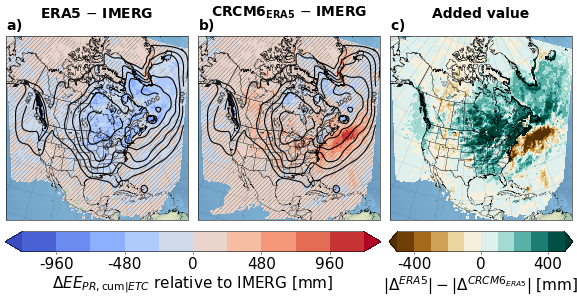

In [4]:
fig, axes, crs = _setup_plot_axes([[x, Y0[0], W, W] for x in X0[:3]], FIGSIZE)
d_era5, d_ubb = D['ERA5'][0], D['UBB'][0]
added_value = np.abs(d_era5) - np.abs(d_ubb)            # > 0: CRCM6-ERA5 closer to IMERG than ERA5
drawn = [draw(axes[0], crs, d_era5, DIFF, CONT, SIG['ERA5']),
         draw(axes[1], crs, d_ubb, DIFF, CONT, SIG['UBB']),
         draw(axes[2], crs, added_value, AV)]
for i, title in enumerate(['ERA5 $-$ IMERG', f'{UBB_LABEL} $-$ IMERG', 'Added value']):
    column_title(fig, X0[i], title, dy=0.018)  # just above the panel letters (wider titles than in Fig. 3)
    letter(axes[i], i)
colour_bar(fig, drawn[0], X0[0], Y0[0], X0[1] + W - X0[0],
           r'$\Delta EE_{PR,\mathrm{cum}|ETC}$ relative to IMERG [mm]', DIFF_STEP)
colour_bar(fig, drawn[2], X0[2], Y0[0], W, r'$|\Delta^{ERA5}| - |\Delta^{CRCM6_{ERA5}}|$ [mm]', AV_STEP)
save(fig, 'fig_PR_vs_IMERG')

## Supplementary figure

Saved /home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/IMERG/figS_terms_PR_vs_IMERG_2001-2014.png


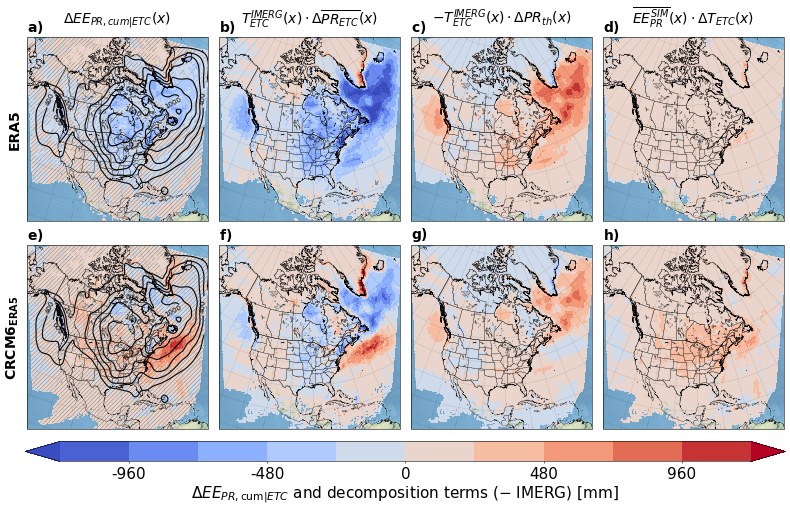

In [5]:
fig, axes, crs = _setup_plot_axes([[x, y, W, W] for y in Y0 for x in X0], FIGSIZE)
for c, title in enumerate(TERM_LABELS):
    column_title(fig, X0[c], title)
for r, (sim, label) in enumerate([('ERA5', 'ERA5'), ('UBB', UBB_LABEL)]):
    row_title(fig, Y0[r], label)
    for c in range(4):
        ax = axes[r * 4 + c]
        drawn = draw(ax, crs, D[sim][c], DIFF, CONT if c == 0 else None, SIG[sim] if c == 0 else None)
        letter(ax, r * 4 + c)
colour_bar(fig, drawn, X0[0], Y0[1], X0[3] + W - X0[0],
           r'$\Delta EE_{PR,\mathrm{cum}|ETC}$ and decomposition terms ($-$ IMERG) [mm]', DIFF_STEP)
save(fig, 'figS_terms_PR_vs_IMERG')